In [1]:
from sklearn.impute import KNNImputer
import numpy as np
import pandas as pd
import glob
import os
from tqdm import tqdm


folder_path = '../data/raw/nasdaq/stocks'
csv_files = glob.glob(os.path.join(folder_path, "*.csv"))

In [3]:
dataframes_list = []
for file in csv_files:
    filename = os.path.basename(file)
    ticker = filename.replace('.csv', '')
    
    df = pd.read_csv(file)
    
    df['Ticker'] = ticker
    
    dataframes_list.append(df)

master_df = pd.concat(dataframes_list, ignore_index=True)

print(master_df.head())

         Date       Open       High        Low      Close  Adj Close   Volume  \
0  2016-01-08  19.162428  19.162428  19.114038  19.114038  11.411459  10300.0   
1  2016-01-11  19.133394  19.230173  19.017258  19.017258  11.353675  49600.0   
2  2016-01-12  19.113070  19.113070  19.103392  19.103392  11.405104   2300.0   
3  2016-01-13  19.103392  19.103392  19.103392  19.103392  11.405104      0.0   
4  2016-01-14  19.065647  19.385021  18.968868  19.104361  11.405683  26100.0   

  Ticker  
0    RIV  
1    RIV  
2    RIV  
3    RIV  
4    RIV  


In [4]:
master_df['Date'] = pd.to_datetime(master_df['Date'])

pivoted_df = master_df.pivot(index='Date', columns='Ticker', values='Adj Close')

pivoted_df = pivoted_df[pivoted_df.index >= '2020-01-01']

print(pivoted_df.head())

Ticker              A         AA  AACG        AAL   AAMC  AAME        AAN  \
Date                                                                        
2020-01-02  85.731819  21.420000  1.35  28.982893  13.17  1.99  57.544491   
2020-01-03  84.355324  21.500000  1.47  27.548195  13.60  2.04  56.846020   
2020-01-06  84.604691  21.000000  1.43  27.219410  13.66  1.86  57.554474   
2020-01-07  84.864029  21.320000  1.43  27.119778  13.90  1.80  57.464668   
2020-01-08  85.701897  20.459999  1.51  27.737495  13.68  1.90  58.472469   

Ticker       AAOI       AAON         AAP  ...  ZSAN        ZTO        ZTR  \
Date                                      ...                               
2020-01-02  12.50  49.889999  158.960907  ...  1.52  23.719999  11.147144   
2020-01-03  12.12  50.349998  158.970871  ...  1.55  23.299999  11.127758   
2020-01-06  12.15  50.259998  156.358261  ...  1.64  23.360001  11.032801   
2020-01-07  12.43  50.150002  154.503510  ...  1.71  23.000000  10.964272  

In [5]:
pivoted_df = pivoted_df.dropna(axis=1, how='all')

pivoted_df = pivoted_df.interpolate(method='time')

imputer = KNNImputer(n_neighbors=5)

imputed_data = imputer.fit_transform(pivoted_df)
clean_df = pd.DataFrame(imputed_data, index=pivoted_df.index, columns=pivoted_df.columns)

In [6]:
markets_csv_path = "../data/raw/polymarket/polymarket_markets.csv" 

events_csv_path = "../data/raw/polymarket/polymarket_events.csv"

poly_raw_folder = "../data/raw/polymarket/markets"

poly_markets_df = pd.read_csv(markets_csv_path, low_memory=False)
poly_events_df = pd.read_csv(events_csv_path, low_memory=False)

all_raw_csvs = glob.glob(os.path.join(poly_raw_folder, "*", "*.csv"))

price_dataframes = []

for file in tqdm(all_raw_csvs): 
    try:
        df = pd.read_csv(file)
        
        market_id = os.path.basename(os.path.dirname(file))
        df['market_id'] = market_id
        
        price_dataframes.append(df)
    except Exception as e:
        print(f"File {file} failed because: {e}")

poly_raw_df = pd.concat(price_dataframes, ignore_index=True)
print(poly_raw_df.columns.tolist())
print(poly_raw_df.head())

100%|███████████████████████████████████| 49429/49429 [00:36<00:00, 1336.37it/s]


['date', 'outcome', 'p_open', 'p_high', 'p_low', 'p_close', 'count', 'odds_close', 'logit_close', 'range_abs', 'range_rel', 'parkinson_var', 'tr', 'atr_7', 'atr_14', 'atr_30', 'atr_rel_7', 'atr_rel_14', 'atr_rel_30', 'roll_std_p_7', 'roll_std_p_14', 'roll_std_p_30', 'roll_std_logit_7', 'roll_std_logit_14', 'roll_std_logit_30', 'market_sum_close', 'market_gap_close', 'market_sum_min_native', 'market_sum_max_native', 'market_gap_maxabs_native', 'market_gap_mean_native', 'trades_count', 'vol_quote', 'vol_base', 'buy_vol_quote', 'sell_vol_quote', 'flow_imbalance', 'avg_trade_size_quote', 'median_trade_size_quote', 'yes_dir_flow_quote', 'yes_dir_flow_base', 'whale_flow_top10p_quote', 'holders_count', 'supply', 'hhi', 'effective_holders', 'top10_share', 'top1_share', 'gini', 'avg_balance', 'median_balance', 'market_id']
         date  outcome  p_open  p_high  p_low  p_close  count  odds_close  \
0  2025-07-28        0   0.185   0.195  0.185    0.195      8    0.242236   
1  2025-07-28       

In [8]:
import json
import pandas as pd
import numpy as np

poly_raw_df['Date'] = pd.to_datetime(poly_raw_df['date'])
if 'p_close' in poly_raw_df.columns:
    poly_raw_df = poly_raw_df.rename(columns={'p_close': 'price'})
poly_raw_df['market_id'] = poly_raw_df['market_id'].astype(str).str.replace('market=', '')

daily_poly_df = poly_raw_df.groupby(['market_id', 'Date']).agg({
    'price': 'last', 
    'vol_quote': 'sum' 
}).reset_index()

daily_poly_df['market_id'] = daily_poly_df['market_id'].astype(str).str.lower().str.strip()

sample_ids = daily_poly_df['market_id'].unique()[:10]
correct_merge_col = None

for col in poly_markets_df.columns:
    if poly_markets_df[col].astype(str).str.lower().str.strip().isin(sample_ids).any():
        correct_merge_col = col
        break

if correct_merge_col is None:
    correct_merge_col = 'questionID'

poly_markets_df[correct_merge_col] = poly_markets_df[correct_merge_col].astype(str).str.lower().str.strip()


def get_settlement(val):
    try:
        if isinstance(val, list):
            return float(val[1])
        elif isinstance(val, str):
            clean_str = val.replace("'", '"')
            prices = json.loads(clean_str)
            return float(prices[1])
    except:
        pass
    return float('nan')

poly_markets_df['final_settlement'] = poly_markets_df['outcomePrices'].apply(get_settlement)


merged_poly = pd.merge(
    daily_poly_df, 
    poly_markets_df[[correct_merge_col, 'umaResolutionStatus', 'final_settlement']], 
    left_on='market_id', 
    right_on=correct_merge_col, 
    how='left'
)

merged_poly = merged_poly[merged_poly['umaResolutionStatus'] == 'resolved'].copy()

merged_poly['Target_Deviation'] = merged_poly['final_settlement'] - merged_poly['price']

merged_poly = merged_poly.dropna(subset=['final_settlement', 'Target_Deviation'])

print(merged_poly[['Date', 'market_id', 'price', 'vol_quote', 'final_settlement', 'Target_Deviation']].head())

          Date                                          market_id  price  \
929 2025-08-05  0x04a1462e83c415194ac700181bd97f97db149fdcfa4f...  0.455   
930 2025-08-06  0x04a1462e83c415194ac700181bd97f97db149fdcfa4f...  0.575   
931 2025-08-07  0x04a1462e83c415194ac700181bd97f97db149fdcfa4f...  0.570   
932 2025-08-08  0x04a1462e83c415194ac700181bd97f97db149fdcfa4f...  0.585   
933 2025-08-09  0x04a1462e83c415194ac700181bd97f97db149fdcfa4f...  0.575   

       vol_quote  final_settlement  Target_Deviation  
929   596.335046               0.0            -0.455  
930  3264.782800               0.0            -0.575  
931   148.860815               0.0            -0.570  
932    14.428758               0.0            -0.585  
933  2429.791523               0.0            -0.575  


In [9]:
from sklearn.preprocessing import StandardScaler, RobustScaler

merged_poly = merged_poly.sort_values(by=['market_id', 'Date'])

merged_poly['price_lag_1d'] = merged_poly.groupby('market_id')['price'].shift(1)
merged_poly['price_lag_3d'] = merged_poly.groupby('market_id')['price'].shift(3)

merged_poly['rolling_volatility_7d'] = merged_poly.groupby('market_id')['price'].transform(lambda x: x.rolling(7).std())

day_of_week = merged_poly['Date'].dt.dayofweek
merged_poly['day_of_week_sin'] = np.sin(day_of_week * (2 * np.pi / 7))
merged_poly['day_of_week_cos'] = np.cos(day_of_week * (2 * np.pi / 7))

final_poly_df = merged_poly.dropna().copy()

print("Normalizing data...")

features_to_scale = ['price', 'vol_quote', 'price_lag_1d', 'price_lag_3d', 'rolling_volatility_7d']

std_scaler = StandardScaler()
std_scaled_features = std_scaler.fit_transform(final_poly_df[features_to_scale])
std_scaled_df = pd.DataFrame(std_scaled_features, columns=[f"{f}_std" for f in features_to_scale], index=final_poly_df.index)

robust_scaler = RobustScaler()
robust_scaled_features = robust_scaler.fit_transform(final_poly_df[features_to_scale])
robust_scaled_df = pd.DataFrame(robust_scaled_features, columns=[f"{f}_robust" for f in features_to_scale], index=final_poly_df.index)

final_poly_ml_ready = pd.concat([final_poly_df, std_scaled_df, robust_scaled_df], axis=1)

print("\nFeature Engineering and Scaling Complete! Here is your ML-ready dataset:")
print(final_poly_ml_ready[['Date', 'market_id', 'Target_Deviation', 'price_std', 'vol_quote_robust', 'day_of_week_sin']].head())

Normalizing data...

Feature Engineering and Scaling Complete! Here is your ML-ready dataset:
          Date                                          market_id  \
935 2025-08-11  0x04a1462e83c415194ac700181bd97f97db149fdcfa4f...   
936 2025-08-12  0x04a1462e83c415194ac700181bd97f97db149fdcfa4f...   
937 2025-08-13  0x04a1462e83c415194ac700181bd97f97db149fdcfa4f...   
938 2025-08-14  0x04a1462e83c415194ac700181bd97f97db149fdcfa4f...   
939 2025-08-15  0x04a1462e83c415194ac700181bd97f97db149fdcfa4f...   

     Target_Deviation  price_std  vol_quote_robust  day_of_week_sin  
935            -0.585  -1.021341          1.806251         0.000000  
936            -0.575  -1.061000          0.645073         0.781831  
937            -0.545  -1.179976          0.537982         0.974928  
938            -0.545  -1.179976         -0.033709         0.433884  
939            -0.545  -1.179976         -0.036742        -0.433884  


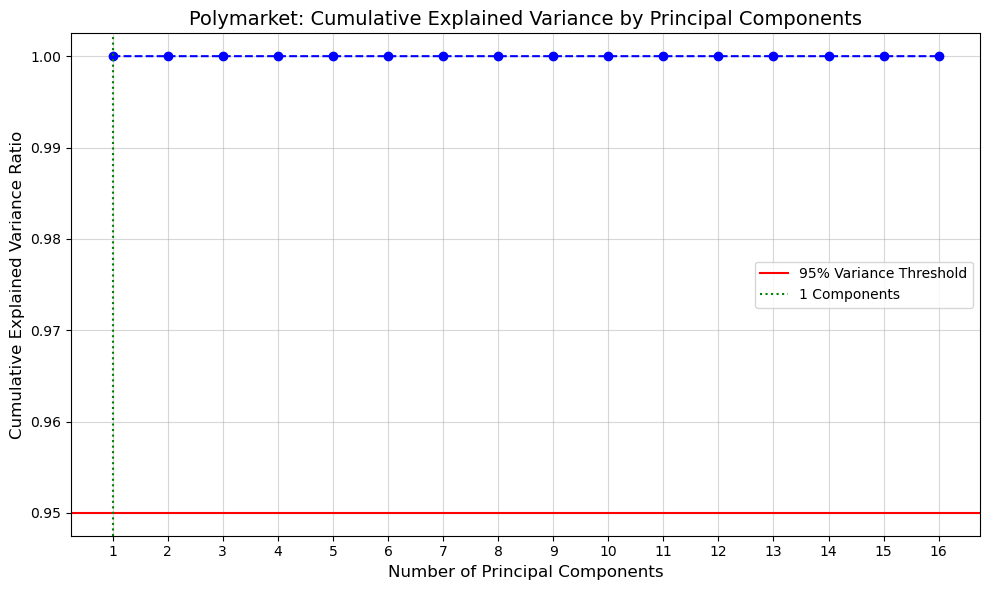

In [10]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

cols_to_drop = [
    'Date', 'market_id', 'conditionId', 'questionID', 
    'umaResolutionStatus', 'Target_Deviation', 'final_settlement', 'price'
]

X_poly = final_poly_ml_ready.drop(columns=[c for c in cols_to_drop if c in final_poly_ml_ready.columns])

X_poly = X_poly.select_dtypes(include=[np.number])

pca = PCA()
pca.fit(X_poly)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1


plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--', color='b')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Variance Threshold')
plt.axvline(x=n_components_95, color='g', linestyle=':', label=f'{n_components_95} Components')

plt.title('Polymarket: Cumulative Explained Variance by Principal Components', fontsize=14)
plt.xlabel('Number of Principal Components', fontsize=12)
plt.ylabel('Cumulative Explained Variance Ratio', fontsize=12)
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

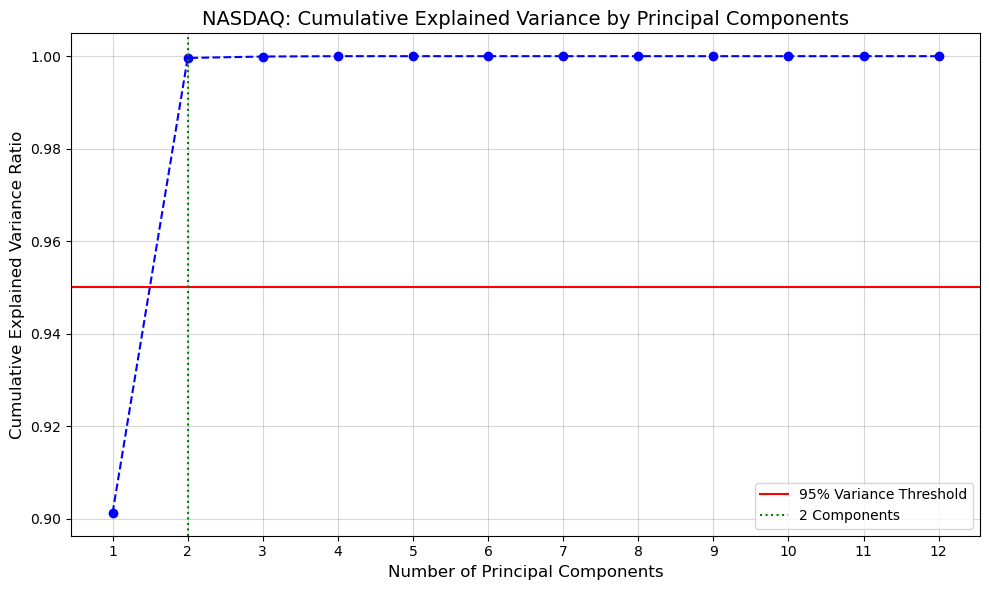

In [11]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

stock_raw_df = master_df.copy()

stock_raw_df.columns = stock_raw_df.columns.str.lower()

stock_raw_df['date'] = pd.to_datetime(stock_raw_df['date'])

stock_raw_df = stock_raw_df[stock_raw_df['close'] > 0].copy()

stock_df = stock_raw_df.sort_values(by=['ticker', 'date']).copy()

stock_df['Target_Log_Return'] = np.log(stock_df['close'] / stock_df.groupby('ticker')['close'].shift(1))
stock_df = stock_df.replace([np.inf, -np.inf], np.nan)

stock_df['price_lag_1d'] = stock_df.groupby('ticker')['close'].shift(1)
stock_df['price_lag_3d'] = stock_df.groupby('ticker')['close'].shift(3)

stock_df['rolling_volatility_7d'] = stock_df.groupby('ticker')['close'].transform(lambda x: x.rolling(7).std())

day_of_week = stock_df['date'].dt.dayofweek
stock_df['day_of_week_sin'] = np.sin(day_of_week * (2 * np.pi / 7))
stock_df['day_of_week_cos'] = np.cos(day_of_week * (2 * np.pi / 7))

final_stock_df = stock_df.dropna().copy()

features_to_scale = ['close', 'volume', 'price_lag_1d', 'price_lag_3d', 'rolling_volatility_7d']

std_scaler = StandardScaler()
std_scaled_features = std_scaler.fit_transform(final_stock_df[features_to_scale])
std_scaled_df = pd.DataFrame(std_scaled_features, columns=[f"{f}_std" for f in features_to_scale], index=final_stock_df.index)

robust_scaler = RobustScaler()
robust_scaled_features = robust_scaler.fit_transform(final_stock_df[features_to_scale])
robust_scaled_df = pd.DataFrame(robust_scaled_features, columns=[f"{f}_robust" for f in features_to_scale], index=final_stock_df.index)

final_stock_ml_ready = pd.concat([
    final_stock_df[['date', 'ticker', 'Target_Log_Return', 'day_of_week_sin', 'day_of_week_cos']], 
    std_scaled_df, 
    robust_scaled_df
], axis=1)

cols_to_drop = ['date', 'ticker', 'Target_Log_Return', 'close', 'volume', 'open', 'high', 'low', 'adj close']
X_stock = final_stock_ml_ready.drop(columns=[c for c in cols_to_drop if c in final_stock_ml_ready.columns])
X_stock = X_stock.select_dtypes(include=[np.number])

pca = PCA()
pca.fit(X_stock)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--', color='b')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Variance Threshold')
plt.axvline(x=n_components_95, color='g', linestyle=':', label=f'{n_components_95} Components')

plt.title('NASDAQ: Cumulative Explained Variance by Principal Components', fontsize=14)
plt.xlabel('Number of Principal Components', fontsize=12)
plt.ylabel('Cumulative Explained Variance Ratio', fontsize=12)
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

In [12]:
import os

os.makedirs('data/cleaned', exist_ok=True)

final_poly_ml_ready.sample(frac=0.05).to_csv('../data/processed/polymarket_sample.csv.gz', index=False, compression='gzip')
final_stock_ml_ready.sample(frac=0.05).to_csv('../data/processed/nasdaq_sample.csv.gz', index=False, compression='gzip')